# 🛒 E-Commerce Customer Segmentation using RFM, K-Means, DBSCAN, PCA & t-SNE

**Objective:** Segment the customers of a UK-based online gift retailer using **RFM analysis** (Recency, Frequency, Monetary), compare two clustering algorithms (**K-Means** and **DBSCAN**), reduce dimensionality with **PCA**, visualise the segments with **t-SNE**, and turn each cluster into an actionable **marketing persona**.

**Dataset:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail) — all transactions between 01/12/2010 and 09/12/2011 for a UK-registered non-store online retailer (541,909 rows, 8 columns).

### Workflow
1. Load & clean the transactions
2. Engineer RFM features per customer
3. Explore distributions, fix skew (log transform), scale
4. K-Means — choose *k* with Elbow, Silhouette, Davies-Bouldin and Calinski-Harabasz
5. DBSCAN — choose `eps` with a k-distance plot + parameter grid
6. PCA — dimensionality reduction, loadings and 2-D projection
7. t-SNE — non-linear visualisation of both clusterings
8. Compare algorithms (ARI, cross-tab)
9. Profile clusters and derive marketing personas + recommended actions
10. Export results

## 1. Setup

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

os.makedirs("images", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

def savefig(name):
    plt.savefig(f"images/{name}.png", bbox_inches="tight", dpi=150)

## 2. Load the data
Reading the `.xlsx` is slow (~30 s), so a CSV copy is cached on first run.

In [2]:
RAW_XLSX = "Online_Retail.xlsx"
CACHE_CSV = "Online_Retail_cache.csv"

if os.path.exists(CACHE_CSV):
    df = pd.read_csv(CACHE_CSV, parse_dates=["InvoiceDate"], dtype={"InvoiceNo": str, "StockCode": str})
else:
    df = pd.read_excel(RAW_XLSX, dtype={"InvoiceNo": str, "StockCode": str})
    df.to_csv(CACHE_CSV, index=False)

print(f"Shape: {df.shape}")
df.head()

Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 33.1 MB


In [4]:
print("Date range :", df["InvoiceDate"].min(), "->", df["InvoiceDate"].max())
print("Customers  :", df["CustomerID"].nunique())
print("Countries  :", df["Country"].nunique())
print("\nMissing values:")
print(df.isna().sum())

Date range : 2010-12-01 08:26:00 -> 2011-12-09 12:50:00
Customers  : 4372
Countries  : 38

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


## 3. Data cleaning
Business rules applied before any modelling:

| Issue | Treatment | Why |
|---|---|---|
| Missing `CustomerID` | drop | cannot attribute purchases to a customer |
| Exact duplicate rows | drop | double-counted lines inflate Monetary |
| `InvoiceNo` starting with **C** | drop | cancellations / returns |
| `Quantity <= 0` or `UnitPrice <= 0` | drop | adjustments, damaged stock, free items |

In [5]:
n0 = len(df)
clean = df.dropna(subset=["CustomerID"])
n1 = len(clean)
clean = clean.drop_duplicates()
n2 = len(clean)
clean = clean[~clean["InvoiceNo"].astype(str).str.startswith("C")]
n3 = len(clean)
clean = clean[(clean["Quantity"] > 0) & (clean["UnitPrice"] > 0)].copy()
n4 = len(clean)

steps = pd.DataFrame({
    "step": ["raw", "drop missing CustomerID", "drop duplicates", "drop cancellations", "drop Quantity/UnitPrice <= 0"],
    "rows_remaining": [n0, n1, n2, n3, n4],
})
steps["rows_removed"] = (-steps["rows_remaining"].diff()).fillna(0).astype(int)
clean["CustomerID"] = clean["CustomerID"].astype(int)
clean["TotalPrice"] = clean["Quantity"] * clean["UnitPrice"]
steps

,step,rows_remaining,rows_removed
0,raw,541909,0
1,drop missing CustomerID,406829,135080
2,drop duplicates,401604,5225
3,drop cancellations,392732,8872
4,drop Quantity/UnitPrice <= 0,392692,40


In [6]:
print(f"Clean transactions : {len(clean):,}")
print(f"Unique customers   : {clean['CustomerID'].nunique():,}")
print(f"Unique invoices    : {clean['InvoiceNo'].nunique():,}")
print(f"Total revenue      : £{clean['TotalPrice'].sum():,.0f}")
print(f"UK share of revenue: {clean.loc[clean.Country=='United Kingdom','TotalPrice'].sum()/clean['TotalPrice'].sum():.1%}")

Clean transactions : 392,692
Unique customers   : 4,338
Unique invoices    : 18,532
Total revenue      : £8,887,209
UK share of revenue: 82.0%


## 4. RFM feature engineering
* **Recency** – days since the customer's last purchase (snapshot = last invoice date + 1 day). *Lower is better.*
* **Frequency** – number of distinct invoices (orders).
* **Monetary** – total spend (£).

In [7]:
snapshot_date = clean["InvoiceDate"].max() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date.date())

rfm = clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
)
print(rfm.shape)
rfm.head(10)

Snapshot date: 2011-12-10


(4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40
12352,36,8,2506.04
12353,204,1,89.00
12354,232,1,1079.40
12355,214,1,459.40


In [8]:
rfm.describe(percentiles=[.25, .5, .75, .95, .99]).round(2)

,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
95%,312.00,13.00,5790.00
99%,369.00,30.00,19780.49
max,374.00,209.00,280206.02


## 5. Exploratory analysis
RFM variables are almost always **right-skewed**. Distance-based algorithms (K-Means, DBSCAN) are sensitive to this, so we check skewness and apply a log transform.

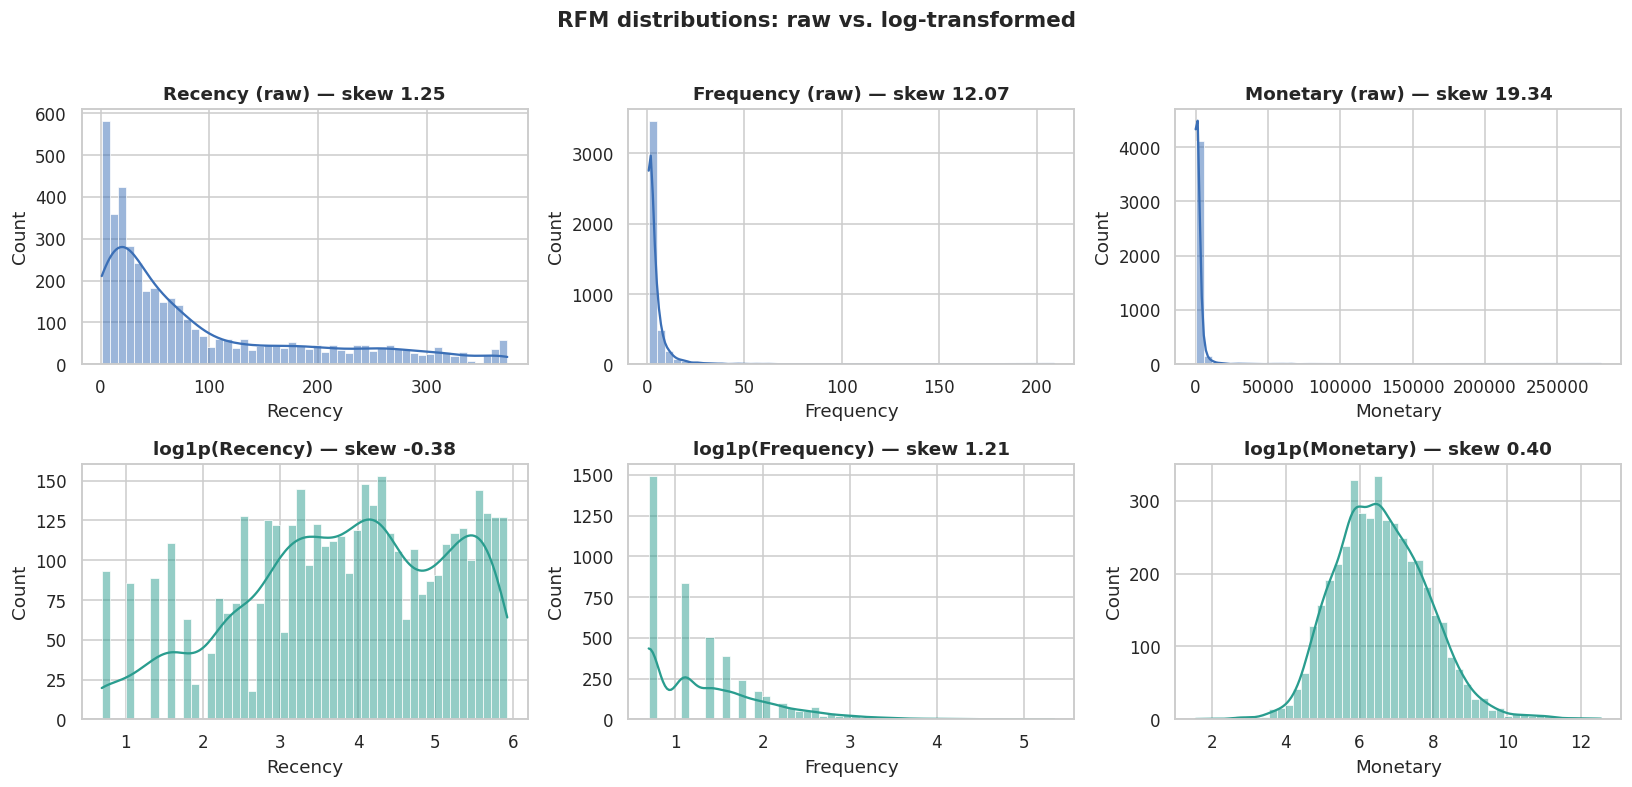

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, col in enumerate(rfm.columns):
    sns.histplot(rfm[col], bins=50, kde=True, ax=axes[0, i], color="#3b6fb6")
    axes[0, i].set_title(f"{col} (raw) — skew {rfm[col].skew():.2f}")
    sns.histplot(np.log1p(rfm[col]), bins=50, kde=True, ax=axes[1, i], color="#2a9d8f")
    axes[1, i].set_title(f"log1p({col}) — skew {np.log1p(rfm[col]).skew():.2f}")
plt.suptitle("RFM distributions: raw vs. log-transformed", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
savefig("01_rfm_distributions")
plt.show()

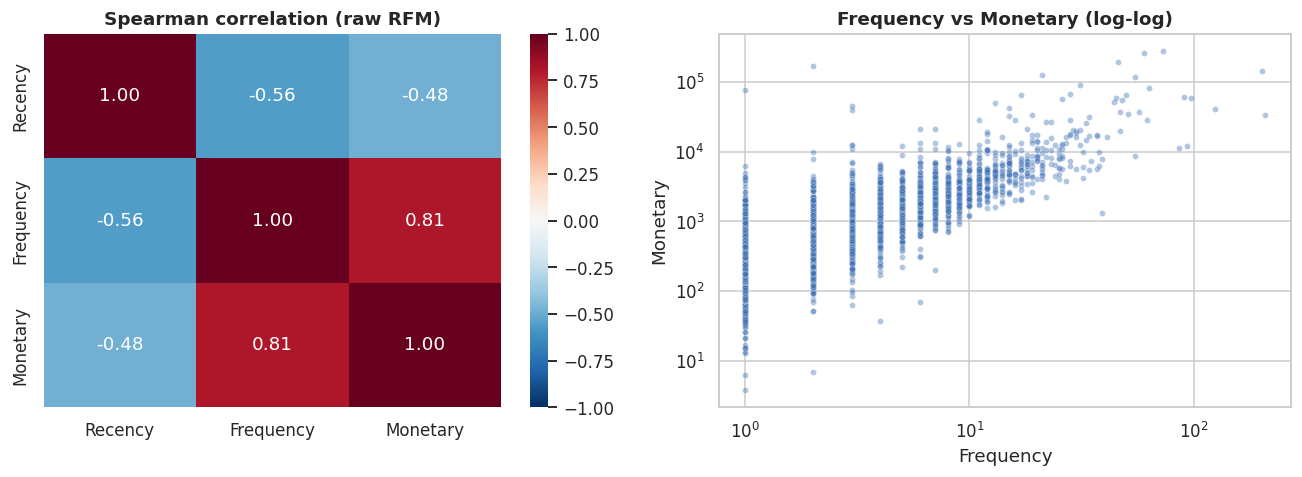

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(rfm.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Spearman correlation (raw RFM)")
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", alpha=.4, s=15, ax=ax[1], color="#3b6fb6")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_title("Frequency vs Monetary (log-log)")
plt.tight_layout()
savefig("02_rfm_correlation")
plt.show()

**Observations**
* Frequency (skew ≈ 12) and Monetary (skew ≈ 19) are extremely right-skewed — a few "whale" customers spend tens of thousands of pounds. After `log1p` the skews drop to ≈ 1.2 and ≈ 0.4; Recency (1.25 → −0.4) is also tamed.
* **Frequency and Monetary are strongly positively correlated (Spearman ≈ 0.81)**, while **Recency is moderately negatively correlated** with both (≈ −0.56 and −0.48): recent customers buy more often and spend more. This redundancy is why PCA compresses RFM so well (Section 8).

## 6. Transform & scale
`log1p` → `StandardScaler` so every dimension has mean 0 and unit variance. Without scaling, Monetary (range up to £280k) would completely dominate the Euclidean distance.

In [11]:
rfm_log = np.log1p(rfm)
scaler = StandardScaler()
X = scaler.fit_transform(rfm_log)
X_df = pd.DataFrame(X, index=rfm.index, columns=rfm.columns)
print("Scaled mean:", X.mean(axis=0).round(3), "| std:", X.std(axis=0).round(3))
X_df.head()

Scaled mean: [-0. -0. -0.] | std: [1. 1. 1.]


,Recency,Frequency,Monetary
CustomerID,,,
12346,1.461993,-0.955214,3.707716
12347,-2.038734,1.074425,1.414903
12348,0.373104,0.386304,0.720024
12349,-0.623086,-0.955214,0.702287
12350,1.424558,-0.955214,-0.614514


## 7. Clustering
### 7.1 K-Means — selecting *k*
We evaluate *k* = 2…10 with four criteria:
* **Inertia** (elbow) — lower is better, look for the bend
* **Silhouette** — higher is better
* **Davies–Bouldin** — lower is better
* **Calinski–Harabasz** — higher is better

In [12]:
K_RANGE = range(2, 11)
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X, km.labels_),
        "davies_bouldin": davies_bouldin_score(X, km.labels_),
        "calinski_harabasz": calinski_harabasz_score(X, km.labels_),
    })
k_metrics = pd.DataFrame(rows).set_index("k")
k_metrics.round(3)

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,6483.589,0.433,0.892,4367.323
3,4869.489,0.337,1.048,3625.303
4,3938.603,0.337,1.011,3328.919
5,3296.709,0.316,0.988,3192.977
6,2855.526,0.313,1.016,3082.283
7,2548.820,0.309,0.982,2963.794
8,2336.341,0.303,0.989,2827.068
9,2156.006,0.281,1.019,2725.196
10,2000.573,0.278,1.024,2647.380


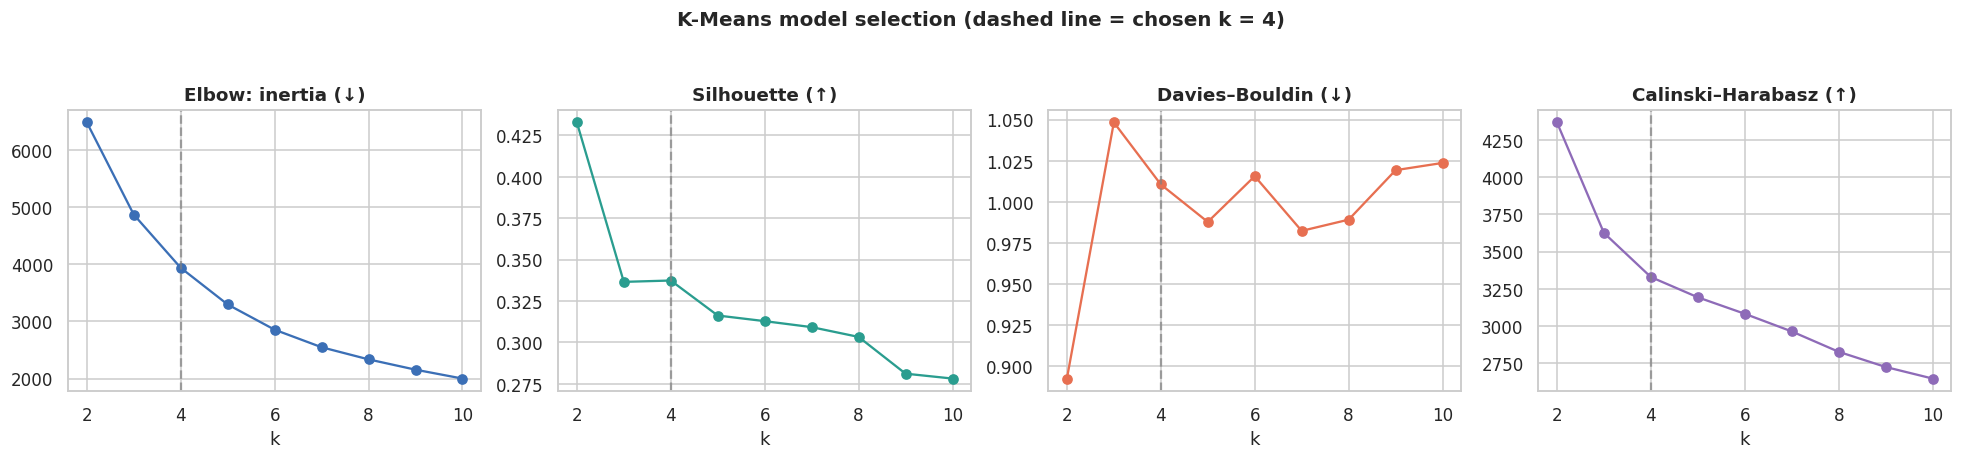

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
specs = [("inertia", "Elbow: inertia (↓)", "#3b6fb6"),
         ("silhouette", "Silhouette (↑)", "#2a9d8f"),
         ("davies_bouldin", "Davies–Bouldin (↓)", "#e76f51"),
         ("calinski_harabasz", "Calinski–Harabasz (↑)", "#8e6bb8")]
for ax, (col, title, c) in zip(axes, specs):
    ax.plot(k_metrics.index, k_metrics[col], "o-", color=c)
    ax.axvline(4, ls="--", color="grey", alpha=.7)
    ax.set_title(title); ax.set_xlabel("k")
plt.suptitle("K-Means model selection (dashed line = chosen k = 4)", fontsize=13, fontweight="bold", y=1.04)
plt.tight_layout()
savefig("03_kmeans_selection")
plt.show()

**Choosing k = 4**

* Silhouette is highest at *k* = 2 (0.43 — a coarse "active vs. lapsed" split, real but not actionable) and then **is identical for *k* = 3 and *k* = 4 (0.337)** before declining slowly.
* The inertia curve has no sharp elbow; the bend is gradual around *k* = 3–5.
* Davies–Bouldin is best for *k* = 2 and then hovers around 1.0 for every *k* ≥ 3; Calinski–Harabasz decreases smoothly (it is biased toward small *k*).

Statistically, *k* = 3–4 is the sweet spot. **We pick *k* = 4** because, with essentially no loss in cluster quality versus *k* = 3, it separates a **mid-tier "growth" segment** from a **recent low-spend segment**, which require different marketing treatment (see Section 11).

In [14]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(X)
rfm["KMeans"] = kmeans.labels_

print(f"Silhouette        : {silhouette_score(X, kmeans.labels_):.3f}")
print(f"Davies-Bouldin    : {davies_bouldin_score(X, kmeans.labels_):.3f}")
print(f"Calinski-Harabasz : {calinski_harabasz_score(X, kmeans.labels_):,.0f}")
print("\nCluster sizes:")
print(rfm["KMeans"].value_counts().sort_index())

Silhouette        : 0.337
Davies-Bouldin    : 1.011
Calinski-Harabasz : 3,329

Cluster sizes:
KMeans
0    1617
1    1173
2     839
3     709
Name: count, dtype: int64


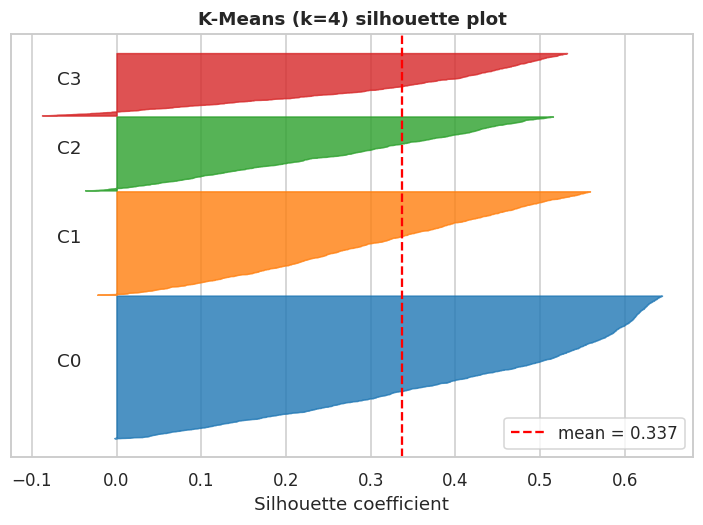

In [15]:
# Per-sample silhouette plot
from sklearn.metrics import silhouette_samples
sil = silhouette_samples(X, kmeans.labels_)
fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 10
palette = sns.color_palette("tab10", K)
for c in range(K):
    vals = np.sort(sil[kmeans.labels_ == c])
    y_upper = y_lower + len(vals)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, color=palette[c], alpha=.8)
    ax.text(-0.07, y_lower + .5 * len(vals), f"C{c}")
    y_lower = y_upper + 10
ax.axvline(sil.mean(), color="red", ls="--", label=f"mean = {sil.mean():.3f}")
ax.set_title("K-Means (k=4) silhouette plot"); ax.set_xlabel("Silhouette coefficient"); ax.set_yticks([])
ax.legend()
savefig("04_kmeans_silhouette")
plt.show()

### 7.2 DBSCAN
DBSCAN needs two hyper-parameters:
* `min_samples` – minimum neighbours for a core point
* `eps` – neighbourhood radius

We first inspect the **k-distance plot** (distance to the *min_samples*-th nearest neighbour, sorted). The "knee" suggests a sensible `eps`. Then we run a small **grid search** and weigh the number of clusters, the share of noise and silhouette (computed on non-noise points only).

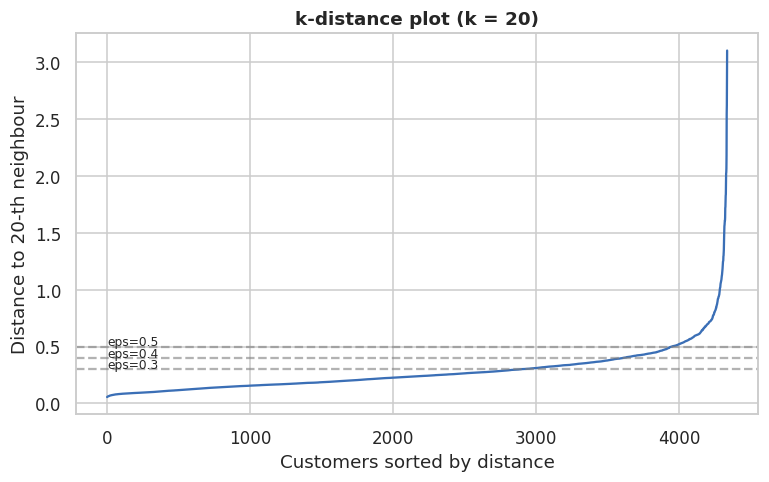

In [16]:
MIN_SAMPLES = 20
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X)
dist, _ = nn.kneighbors(X)
kdist = np.sort(dist[:, -1])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(kdist, color="#3b6fb6")
for e in (0.3, 0.4, 0.5):
    ax.axhline(e, ls="--", color="grey", alpha=.6); ax.text(0, e + .01, f"eps={e}", fontsize=8)
ax.set_title(f"k-distance plot (k = {MIN_SAMPLES})")
ax.set_xlabel("Customers sorted by distance"); ax.set_ylabel(f"Distance to {MIN_SAMPLES}-th neighbour")
savefig("05_dbscan_kdistance")
plt.show()

In [17]:
grid = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for ms in [5, 10, 20, 30]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        mask = lab != -1
        n_clu = len(set(lab[mask]))
        sil_db = silhouette_score(X[mask], lab[mask]) if n_clu > 1 else np.nan
        grid.append({"eps": eps, "min_samples": ms, "n_clusters": n_clu,
                     "noise_%": round((~mask).mean() * 100, 1),
                     "silhouette(non-noise)": round(sil_db, 3) if n_clu > 1 else np.nan})
grid = pd.DataFrame(grid)
grid.pivot(index="eps", columns="min_samples", values="n_clusters").rename_axis(None).rename_axis(None, axis=1)

,5,10,20,30
0.2,32,14,5,4
0.3,8,6,5,4
0.4,6,3,3,3
0.5,2,2,2,2
0.6,2,1,1,1


In [18]:
grid.sort_values(["eps", "min_samples"]).reset_index(drop=True)

,eps,min_samples,n_clusters,noise_%,silhouette(non-noise)
0,0.2,5,32,14.6,-0.030
1,0.2,10,14,30.0,0.074
2,0.2,20,5,50.8,0.157
3,0.2,30,4,64.0,0.217
4,0.3,5,8,5.7,0.063
5,0.3,10,6,10.3,0.088
6,0.3,20,5,19.6,0.124
7,0.3,30,4,30.0,0.162
8,0.4,5,6,2.3,0.067
9,0.4,10,3,3.8,0.175


**Choosing `eps = 0.4`, `min_samples = 20`**

* `eps ≤ 0.3` either fragments the data into many small clusters (up to 32) or, with `min_samples ≥ 20`, labels 20–64 % of customers as noise.
* `eps ≥ 0.5` merges everything into 1–2 blobs — the dense RFM cloud is almost continuous, so DBSCAN can't find natural gaps. (The 0.567 silhouette at `eps=0.6, min_samples=5` is misleading: it is one giant cluster plus 5 outliers.)
* `eps = 0.4, min_samples = 20` is the best compromise: **3 clusters with 7 % noise** and a silhouette of ≈ 0.19 on non-noise points. Silhouette is only modest because the density clusters touch each other; the noise points correspond to genuine extreme customers (checked below).

In [19]:
EPS = 0.4
dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(X)
rfm["DBSCAN"] = dbscan.labels_

mask = rfm["DBSCAN"] != -1
print(f"Clusters found : {rfm.loc[mask, 'DBSCAN'].nunique()}")
print(f"Noise points   : {(~mask).sum()} ({(~mask).mean():.1%})")
print(f"Silhouette (non-noise): {silhouette_score(X[mask.values], rfm.loc[mask, 'DBSCAN']):.3f}")
print()
print(rfm["DBSCAN"].value_counts().sort_index().rename("customers").to_frame())

Clusters found : 3
Noise points   : 305 (7.0%)
Silhouette (non-noise): 0.186

        customers
DBSCAN           
-1            305
 0           1793
 1           1438
 2            802


In [20]:
# What are the DBSCAN 'noise' customers?
rfm.groupby(rfm["DBSCAN"].map(lambda v: "Noise (-1)" if v == -1 else f"Cluster {v}"))[["Recency", "Frequency", "Monetary"]] \
   .agg(["median", "mean"]).round(1)

Recency        Frequency       Monetary         
            median   mean    median  mean   median     mean
DBSCAN                                                     
Cluster 0     25.0   44.5       5.0   5.9   1545.6   2066.9
Cluster 1    138.0  160.2       1.0   1.0    256.3    337.7
Cluster 2     64.0   95.9       2.0   2.0    543.8    632.9
Noise (-1)     9.0   47.2       7.0  15.8   4748.5  13731.5

DBSCAN noise is not "garbage" here: the noise group has a median Monetary of ≈ £4.7k (mean ≈ £13.7k) and a median Recency of 9 days — it is dominated by **extreme-value customers** (very high Frequency/Monetary), plus a few atypical accounts such as a one-off £77k purchase made almost a year ago. That is a useful by-product — DBSCAN works as an **outlier detector** that flags accounts for manual / key-account treatment, while K-Means gives a complete partition of the base.

## 8. Dimensionality reduction with PCA
Even though RFM only has 3 dimensions, PCA tells us how much *independent* information it contains, and gives us an interpretable 2-D projection of the clusters.

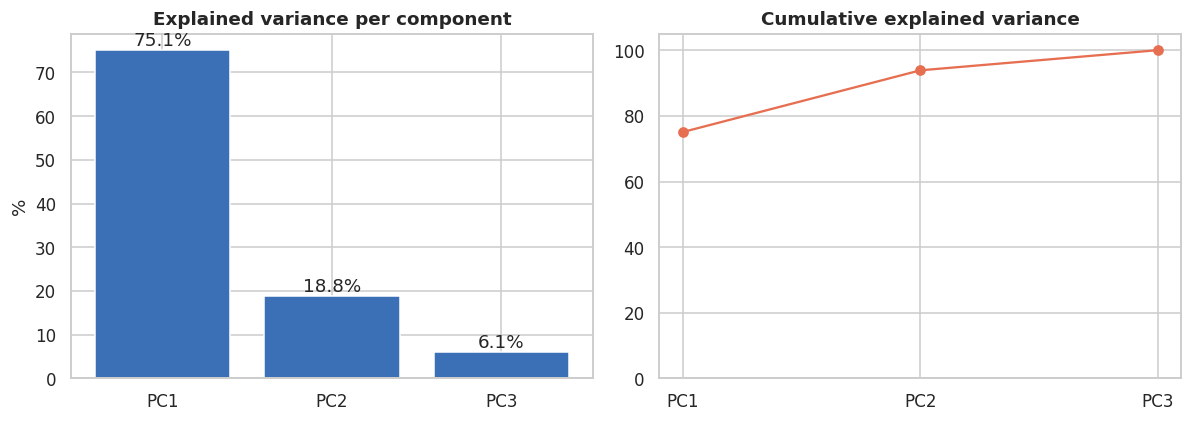

Cumulative variance:  [ 75.1  93.9 100. ]


In [21]:
pca_full = PCA(n_components=3, random_state=RANDOM_STATE).fit(X)
evr = pca_full.explained_variance_ratio_

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(["PC1", "PC2", "PC3"], evr * 100, color="#3b6fb6")
for i, v in enumerate(evr * 100): ax[0].text(i, v + 1, f"{v:.1f}%", ha="center")
ax[0].set_title("Explained variance per component"); ax[0].set_ylabel("%")
ax[1].plot(["PC1", "PC2", "PC3"], np.cumsum(evr) * 100, "o-", color="#e76f51")
ax[1].set_title("Cumulative explained variance"); ax[1].set_ylim(0, 105)
plt.tight_layout()
savefig("06_pca_variance")
plt.show()

print("Cumulative variance: ", (np.cumsum(evr) * 100).round(1))

In [22]:
loadings = pd.DataFrame(pca_full.components_.T, index=rfm.columns[:3], columns=["PC1", "PC2", "PC3"]).round(3)
loadings

,PC1,PC2,PC3
Recency,-0.512,0.850,0.127
Frequency,0.618,0.261,0.741
Monetary,0.597,0.458,-0.659


**Interpretation**
* **PC1 (75 % of variance) is an "engagement / value" axis**: Frequency (+0.62) and Monetary (+0.60) load positively, Recency (−0.51) negatively. High PC1 = recent, frequent, high-spending customers.
* **PC2 (19 %) is dominated by Recency (+0.85)**, i.e. *staleness* — how long ago the customer last bought, independent of how much they spent.
* PC3 (6 %) mainly separates Frequency from Monetary (basket size vs. order count) and can be dropped. Two components retain **93.9 %** of the variance, so a 2-D PCA plot is a faithful picture of the data, and K-Means on the 2-D projection reproduces the 3-D clustering almost exactly (ARI ≈ 0.96, see below).

In [23]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X)
rfm["PC1"], rfm["PC2"] = Z[:, 0], Z[:, 1]
print("Variance explained by 2 PCs: %.1f%%" % (pca.explained_variance_ratio_.sum() * 100))

Variance explained by 2 PCs: 93.9%


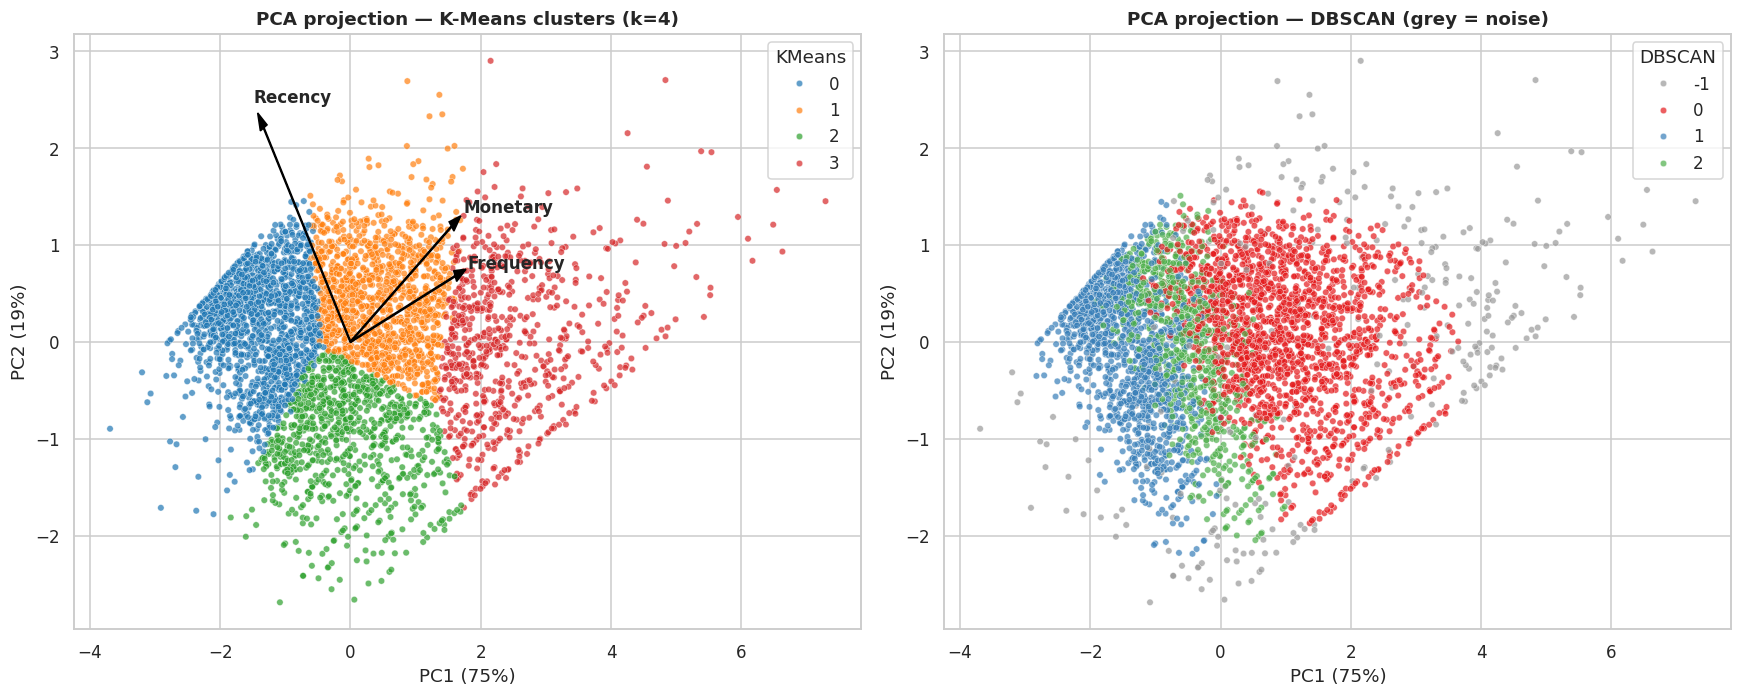

In [24]:
def biplot_arrows(ax, scale=2.6):
    for i, feat in enumerate(rfm.columns[:3]):
        ax.arrow(0, 0, pca.components_[0, i] * scale, pca.components_[1, i] * scale,
                 color="black", width=0.012, head_width=0.12, zorder=5)
        ax.text(pca.components_[0, i] * scale * 1.12, pca.components_[1, i] * scale * 1.12,
                feat, fontsize=11, fontweight="bold", zorder=6)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
sns.scatterplot(data=rfm, x="PC1", y="PC2", hue="KMeans", palette="tab10", s=18, alpha=.7, ax=axes[0])
biplot_arrows(axes[0])
axes[0].set_title("PCA projection — K-Means clusters (k=4)")

db_palette = {-1: "#999999", **{i: c for i, c in enumerate(sns.color_palette("Set1", 8))}}
sns.scatterplot(data=rfm, x="PC1", y="PC2", hue="DBSCAN", palette=db_palette, s=18, alpha=.7, ax=axes[1])
axes[1].set_title("PCA projection — DBSCAN (grey = noise)")
for a in axes:
    a.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); a.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.tight_layout()
savefig("07_pca_clusters")
plt.show()

In [25]:
# Does clustering in PCA space agree with clustering in the original scaled space?
km_pca = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(Z)
print("ARI (K-Means on 3-D scaled RFM vs K-Means on 2-D PCA):", round(adjusted_rand_score(rfm["KMeans"], km_pca.labels_), 3))
print("Silhouette on 2-D PCA space:", round(silhouette_score(Z, km_pca.labels_), 3))

ARI (K-Means on 3-D scaled RFM vs K-Means on 2-D PCA): 0.957


Silhouette on 2-D PCA space: 0.382


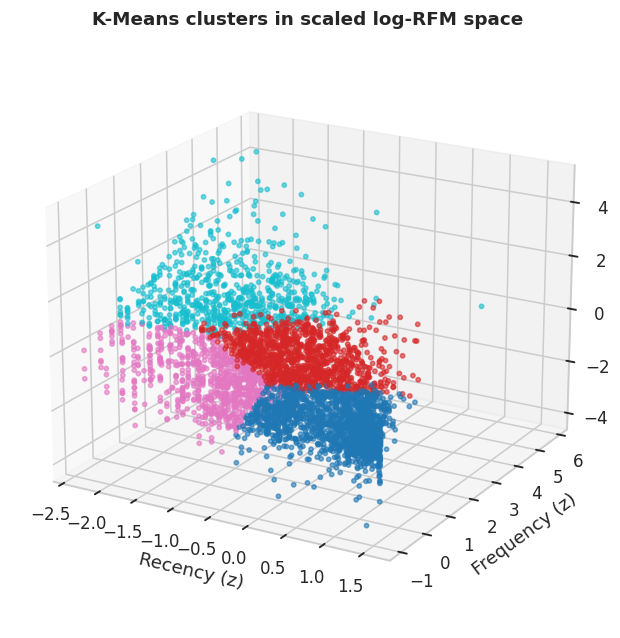

In [26]:
# 3-D view of the scaled RFM space
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
sc = ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=rfm["KMeans"], cmap="tab10", s=8, alpha=.6)
ax.set_xlabel("Recency (z)"); ax.set_ylabel("Frequency (z)"); ax.set_zlabel("Monetary (z)")
ax.set_title("K-Means clusters in scaled log-RFM space"); ax.view_init(elev=20, azim=-60)
savefig("08_rfm_3d")
plt.show()

## 9. Non-linear visualisation with t-SNE
PCA is linear; **t-SNE** preserves *local* neighbourhoods and can reveal structure PCA flattens. Note that distances *between* t-SNE blobs and blob sizes are not meaningful — it's a visual aid, not a clustering method.

First, a quick perplexity sensitivity check.

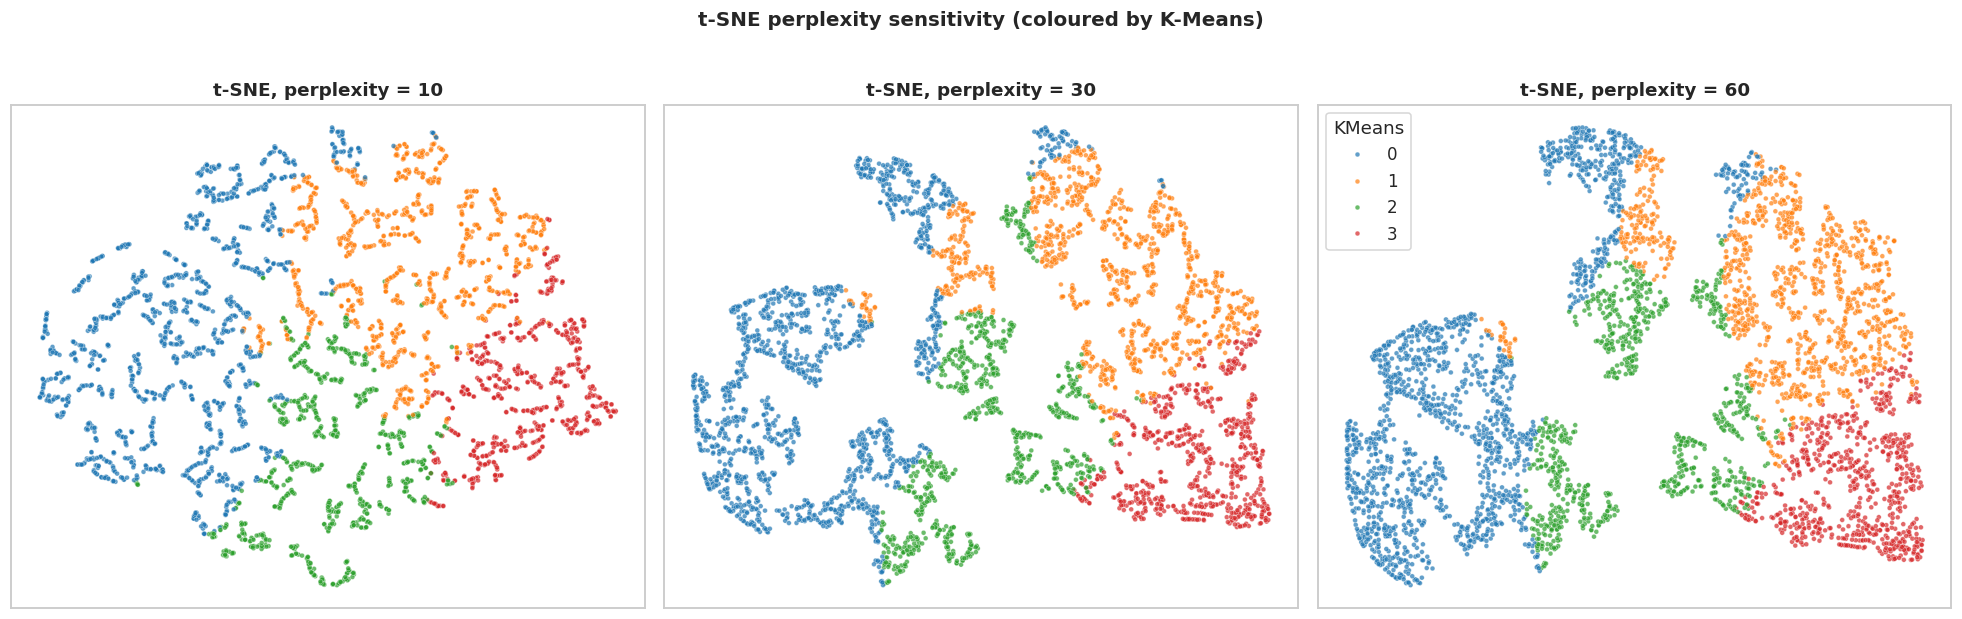

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, perp in zip(axes, [10, 30, 60]):
    emb = TSNE(n_components=2, perplexity=perp, init="pca", learning_rate="auto",
               random_state=RANDOM_STATE).fit_transform(X)
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=rfm["KMeans"], palette="tab10", s=10, alpha=.7, ax=ax, legend=(perp == 60))
    ax.set_title(f"t-SNE, perplexity = {perp}"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("t-SNE perplexity sensitivity (coloured by K-Means)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
savefig("09_tsne_perplexity")
plt.show()

In [28]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
            max_iter=1500, random_state=RANDOM_STATE)
T = tsne.fit_transform(X)
rfm["TSNE1"], rfm["TSNE2"] = T[:, 0], T[:, 1]
print("Final KL divergence:", round(tsne.kl_divergence_, 4))

Final KL divergence: 0.7356


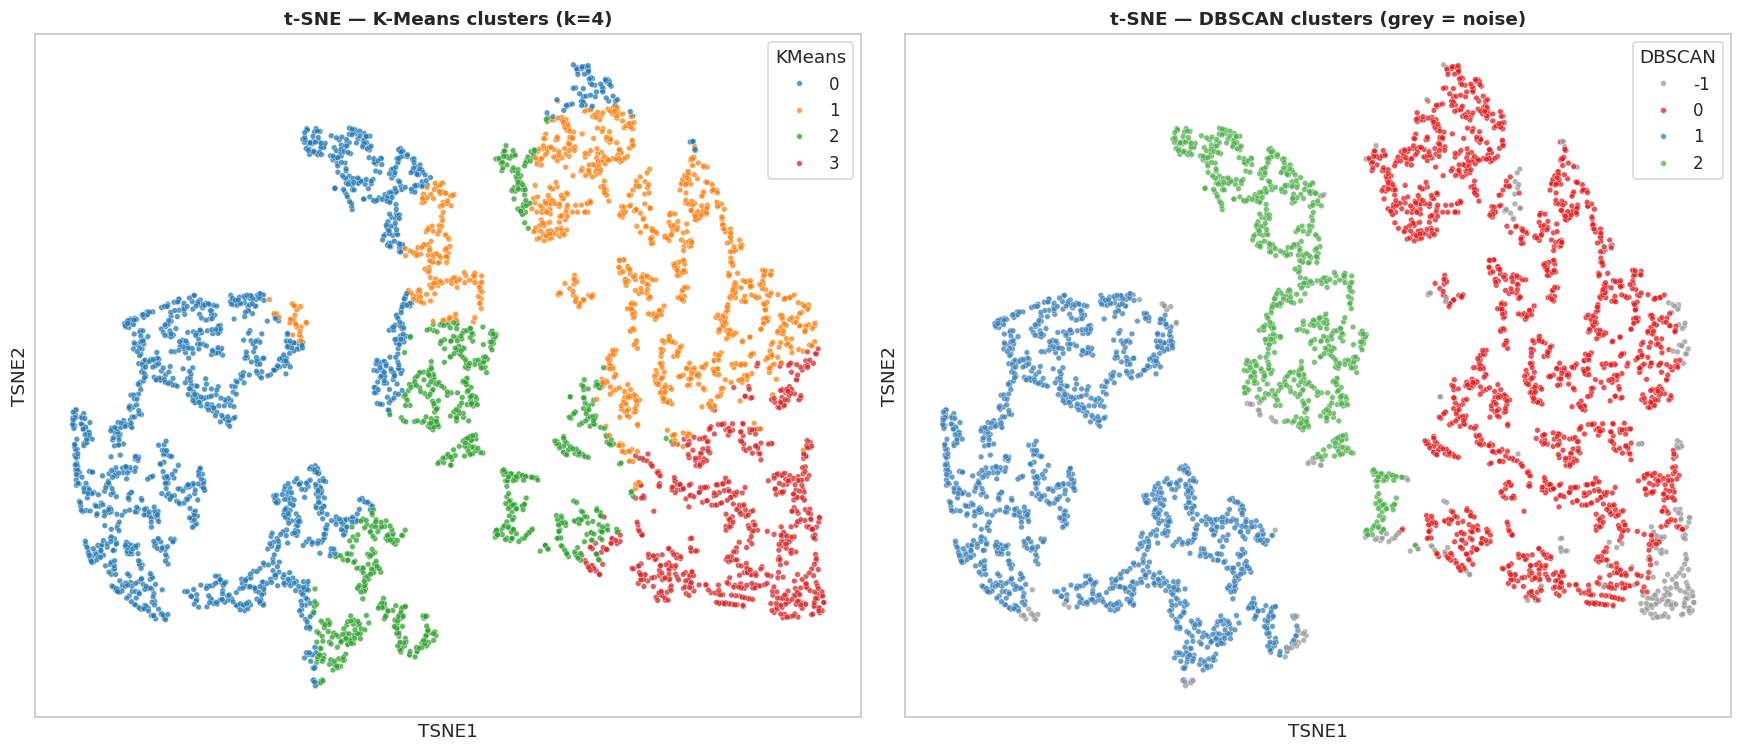

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.scatterplot(data=rfm, x="TSNE1", y="TSNE2", hue="KMeans", palette="tab10", s=14, alpha=.75, ax=axes[0])
axes[0].set_title("t-SNE — K-Means clusters (k=4)")
sns.scatterplot(data=rfm, x="TSNE1", y="TSNE2", hue="DBSCAN", palette=db_palette, s=14, alpha=.75, ax=axes[1])
axes[1].set_title("t-SNE — DBSCAN clusters (grey = noise)")
for a in axes: a.set_xticks([]); a.set_yticks([])
plt.tight_layout()
savefig("10_tsne_clusters")
plt.show()

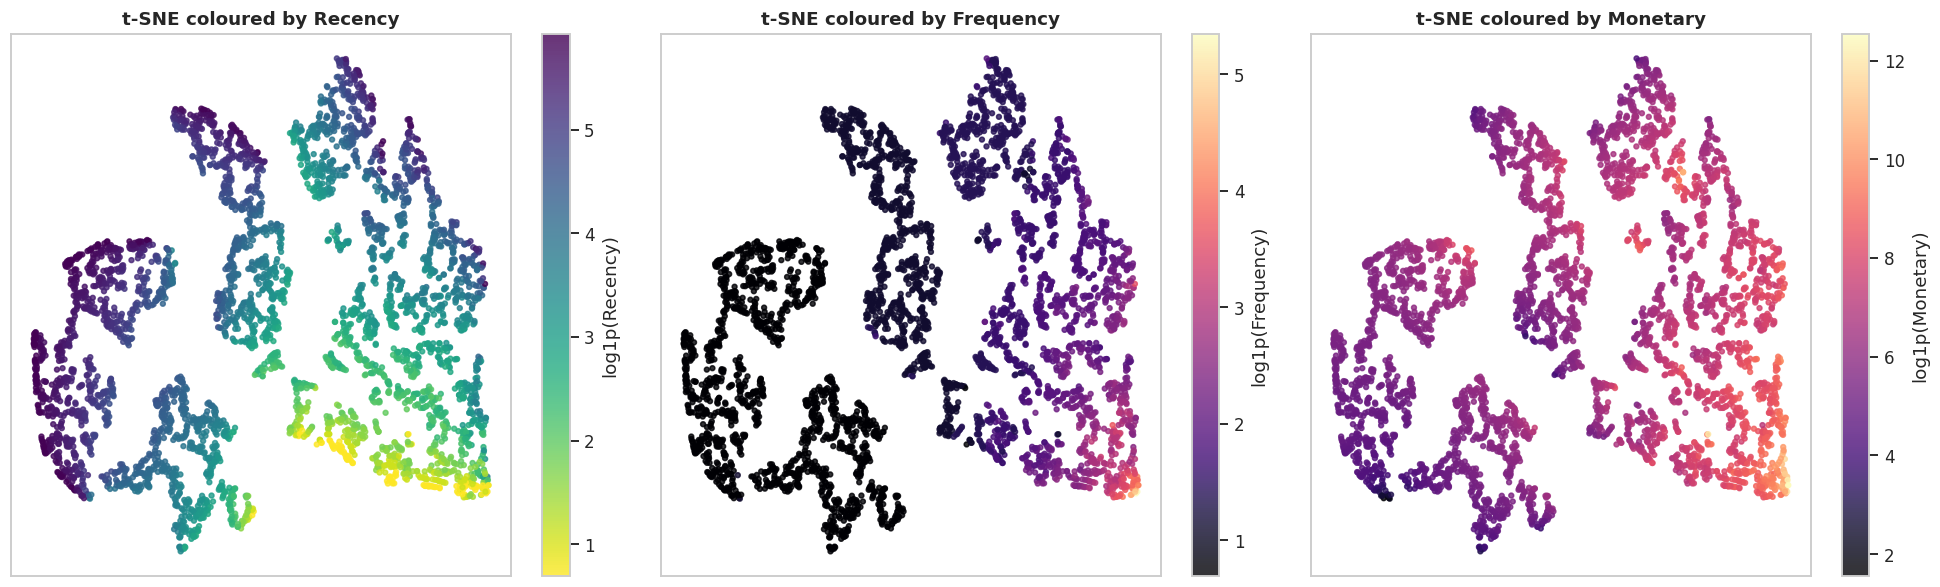

In [30]:
# Colour the same t-SNE map by the raw RFM values to see *why* the map is organised the way it is
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, col, cmap in zip(axes, ["Recency", "Frequency", "Monetary"], ["viridis_r", "magma", "magma"]):
    vals = np.log1p(rfm[col])
    sc = ax.scatter(rfm["TSNE1"], rfm["TSNE2"], c=vals, cmap=cmap, s=10, alpha=.8)
    plt.colorbar(sc, ax=ax, label=f"log1p({col})")
    ax.set_title(f"t-SNE coloured by {col}"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
savefig("11_tsne_by_rfm")
plt.show()

**What the t-SNE map shows**
* The data forms a **continuous manifold ordered by customer value**, not four isolated islands — consistent with the modest silhouette (~0.34) and with DBSCAN's difficulty finding gaps.
* In this run K-Means cluster 0 (lapsed, low-spend) forms a clearly separated region on the left, while clusters 1 and 3 (mid-tier and high-value) occupy the right. Cluster 2 (recent, small baskets) is the **least cleanly separated** — it is scattered between the others, which is expected for a transitional "new customer" group.
* DBSCAN's grey noise points sit on the **periphery of the map**, concentrated in the high-value corner — extreme customers.

## 10. K-Means vs DBSCAN — agreement

In [31]:
m = rfm["DBSCAN"] != -1
print("Adjusted Rand Index (non-noise only):", round(adjusted_rand_score(rfm.loc[m, "KMeans"], rfm.loc[m, "DBSCAN"]), 3))
ct = pd.crosstab(rfm["KMeans"], rfm["DBSCAN"].map(lambda v: "Noise" if v == -1 else f"DB-{v}"))
ct

Adjusted Rand Index (non-noise only): 0.343


DBSCAN,DB-0,DB-1,DB-2,Noise
KMeans,,,,
0,65,1178,345,29
1,945,19,155,54
2,227,241,302,69
3,556,0,0,153


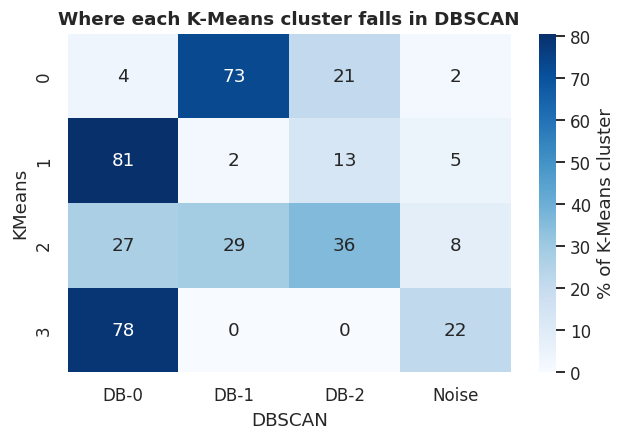

In [32]:
plt.figure(figsize=(6.5, 4))
sns.heatmap(ct.div(ct.sum(axis=1), axis=0) * 100, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of K-Means cluster"})
plt.title("Where each K-Means cluster falls in DBSCAN")
savefig("12_kmeans_vs_dbscan")
plt.show()

| | **K-Means** | **DBSCAN** |
|---|---|---|
| Output | full partition, every customer assigned | clusters + noise label |
| Cluster shape | spherical / equal-variance | arbitrary, density based |
| Parameters | *k* (intuitive, business-driven) | `eps`, `min_samples` (sensitive) |
| On RFM data | works well — smooth continuum is sliced into value tiers | struggles — no density gaps, results change a lot with `eps` |
| Best use here | **segmentation & persona building** | **outlier / VIP-whale detection** |

The two methods only partly agree (ARI ≈ 0.34 on non-noise points): DBSCAN's three density clusters are essentially "lapsed one-timers" (DB-1), "mid-value repeat buyers" (DB-0) and "low-recency / low-spend" (DB-2), and it cannot split the high-value end of the base as finely as K-Means does.

**Decision:** K-Means (k = 4) is used for personas; DBSCAN noise is used as a secondary *outlier flag*.

## 11. Cluster profiling & marketing personas
### 11.1 Profile each K-Means cluster in original business units

In [33]:
prof = rfm.groupby("KMeans").agg(
    Customers=("Recency", "size"),
    Recency_median=("Recency", "median"),
    Frequency_median=("Frequency", "median"),
    Monetary_median=("Monetary", "median"),
    Monetary_mean=("Monetary", "mean"),
    Revenue=("Monetary", "sum"),
)
prof["Customers_%"] = prof["Customers"] / prof["Customers"].sum() * 100
prof["Revenue_%"] = prof["Revenue"] / prof["Revenue"].sum() * 100
prof["Avg_order_value"] = prof["Revenue"] / rfm.groupby("KMeans")["Frequency"].sum()
prof.round(1)

,Customers,Recency_median,Frequency_median,Monetary_median,Monetary_mean,Revenue,Customers_%,Revenue_%,Avg_order_value
KMeans,,,,,,,,,
0,1617,177.0,1.0,298.4,347.8,562469.2,37.3,6.3,263.7
1,1173,55.0,4.0,1341.6,1804.8,2117050.0,27.0,23.8,438.9
2,839,17.0,2.0,466.7,543.1,455624.6,19.3,5.1,253.7
3,709,8.0,10.0,3722.8,8112.9,5752065.1,16.3,64.7,588.2


### 11.2 Name the personas
Names are assigned **by rule from the cluster centroids** (not hard-coded to cluster IDs), so the notebook stays correct if cluster numbering changes between runs:

* highest Monetary → **Champions**
* highest Recency (longest since last purchase) → **Hibernating / Lapsed**
* of the two remaining, higher Monetary → **Potential Loyalists**
* the other → **New & Recent Shoppers**

In [34]:
p = prof.copy()
names = {}
names[p["Monetary_median"].idxmax()] = "Champions"
names[p["Recency_median"].idxmax()] = "Hibernating / Lapsed"
rest = [c for c in p.index if c not in names]
names[p.loc[rest, "Monetary_median"].idxmax()] = "Potential Loyalists"
names[p.loc[rest, "Monetary_median"].idxmin()] = "New & Recent Shoppers"

rfm["Persona"] = rfm["KMeans"].map(names)
prof["Persona"] = prof.index.map(names)

persona_order = ["Champions", "Potential Loyalists", "New & Recent Shoppers", "Hibernating / Lapsed"]
persona_colors = {"Champions": "#2a9d8f", "Potential Loyalists": "#3b6fb6",
                  "New & Recent Shoppers": "#e9c46a", "Hibernating / Lapsed": "#e76f51"}

summary = (prof.set_index("Persona").loc[persona_order]
           [["Customers", "Customers_%", "Recency_median", "Frequency_median", "Monetary_median", "Avg_order_value", "Revenue_%"]]
           .round(1))
summary

,Customers,Customers_%,Recency_median,Frequency_median,Monetary_median,Avg_order_value,Revenue_%
Persona,,,,,,,
Champions,709,16.3,8.0,10.0,3722.8,588.2,64.7
Potential Loyalists,1173,27.0,55.0,4.0,1341.6,438.9,23.8
New & Recent Shoppers,839,19.3,17.0,2.0,466.7,253.7,5.1
Hibernating / Lapsed,1617,37.3,177.0,1.0,298.4,263.7,6.3


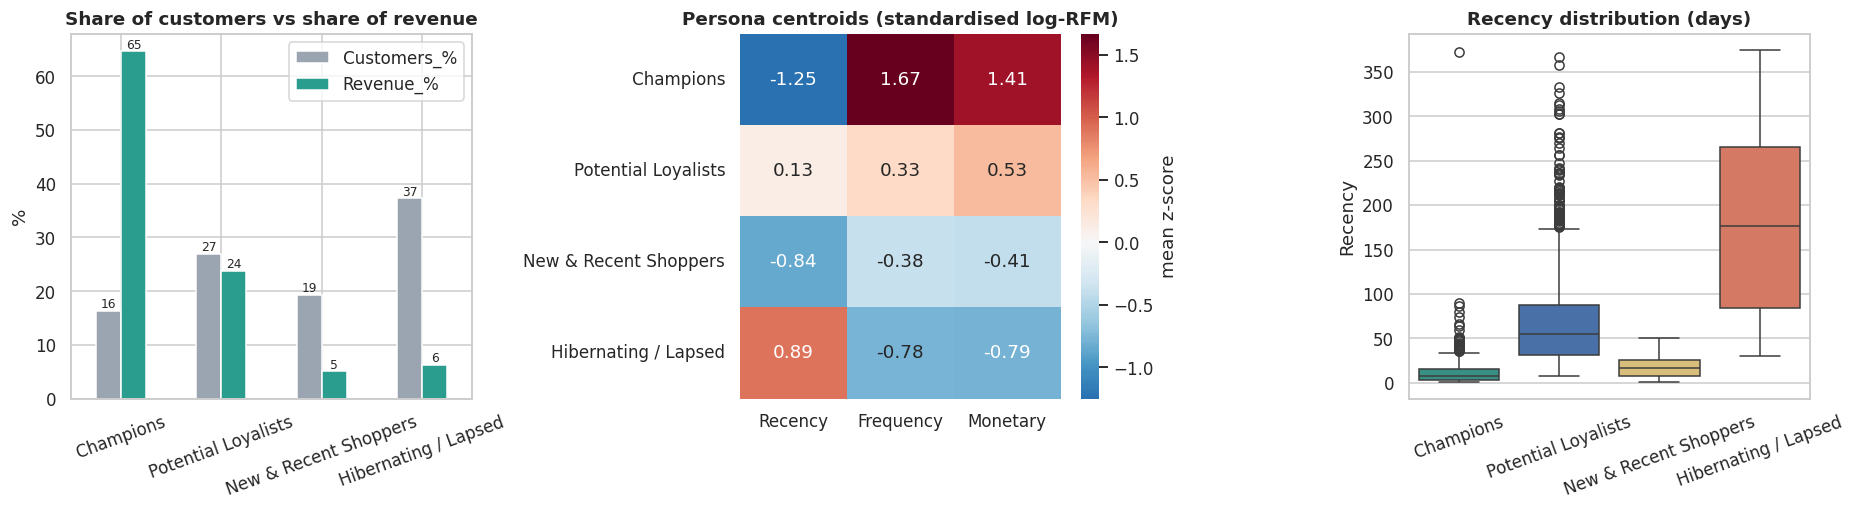

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# 1. Customers vs revenue share
share = summary[["Customers_%", "Revenue_%"]]
share.plot(kind="bar", ax=axes[0], color=["#9aa5b1", "#2a9d8f"], rot=20)
axes[0].set_title("Share of customers vs share of revenue"); axes[0].set_ylabel("%"); axes[0].set_xlabel("")
for cont in axes[0].containers: axes[0].bar_label(cont, fmt="%.0f", fontsize=8)

# 2. Heatmap of centroid z-scores
cent = pd.DataFrame(X, index=rfm.index, columns=["Recency", "Frequency", "Monetary"]).groupby(rfm["Persona"]).mean().loc[persona_order]
sns.heatmap(cent, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1], cbar_kws={"label": "mean z-score"})
axes[1].set_title("Persona centroids (standardised log-RFM)"); axes[1].set_ylabel("")

# 3. Boxplots of recency
sns.boxplot(data=rfm, x="Persona", y="Recency", order=persona_order, palette=persona_colors, ax=axes[2])
axes[2].set_title("Recency distribution (days)"); axes[2].tick_params(axis="x", rotation=20); axes[2].set_xlabel("")
plt.tight_layout()
savefig("13_persona_profile")
plt.show()

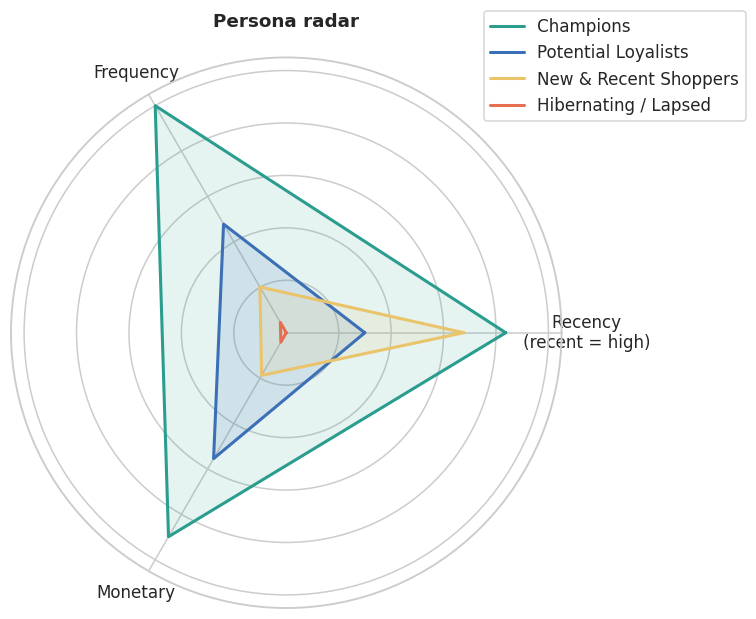

In [36]:
# Radar chart of normalised centroids (Recency inverted so that "outward" is always "better")
cn = cent.copy()
cn["Recency"] = -cn["Recency"]
cn = (cn - cn.min().min()) / (cn.max().max() - cn.min().min())
labels = ["Recency\n(recent = high)", "Frequency", "Monetary"]
angles = np.linspace(0, 2 * np.pi, 3, endpoint=False).tolist(); angles += angles[:1]

fig, ax = plt.subplots(figsize=(6.5, 6.5), subplot_kw=dict(polar=True))
for persona in persona_order:
    vals = cn.loc[persona].tolist(); vals += vals[:1]
    ax.plot(angles, vals, color=persona_colors[persona], lw=2, label=persona)
    ax.fill(angles, vals, color=persona_colors[persona], alpha=.12)
ax.set_xticks(angles[:-1]); ax.set_xticklabels(labels); ax.set_yticklabels([])
ax.set_title("Persona radar", pad=20); ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1))
savefig("14_persona_radar")
plt.show()

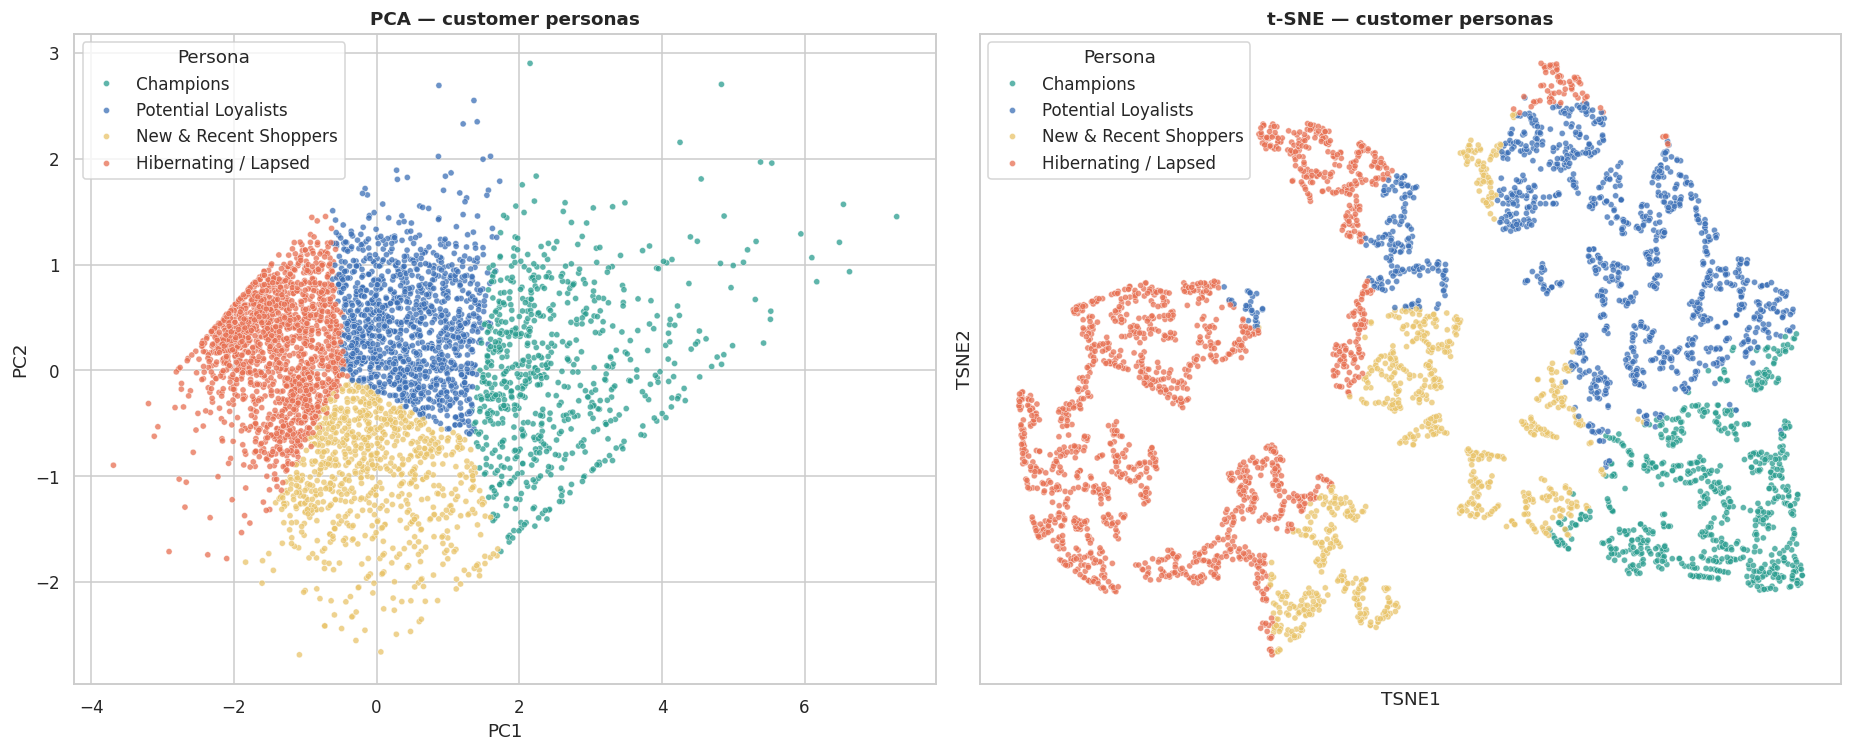

In [37]:
# Final labelled PCA + t-SNE maps with persona names
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, (x, y, title) in zip(axes, [("PC1", "PC2", "PCA"), ("TSNE1", "TSNE2", "t-SNE")]):
    sns.scatterplot(data=rfm, x=x, y=y, hue="Persona", hue_order=persona_order, palette=persona_colors, s=16, alpha=.75, ax=ax)
    ax.set_title(f"{title} — customer personas")
    if title == "t-SNE": ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
savefig("15_personas_pca_tsne")
plt.show()

### 11.3 Persona cards & recommended marketing actions
The figures below are computed live from the data.

In [38]:
actions = {
 "Champions": dict(
    who="Buy very recently (median 8 days ago), order often, highest basket totals. Many are probably trade / wholesale buyers rather than individual shoppers.",
    goal="Retain & reward; grow share of wallet.",
    actions=["VIP / trade-account programme with tiered volume discounts and early access to new ranges",
             "Dedicated account manager or priority customer service",
             "Referral & ambassador incentives — they are the best source of look-alike customers",
             "Avoid blanket discounting: protect margin, reward with access and service, not price cuts"],
    kpi="Retention rate, revenue per customer, referral count"),
 "Potential Loyalists": dict(
    who="Mid-range spenders with a moderate purchase cadence; engaged but not yet habitual.",
    goal="Increase frequency and move them up to Champions.",
    actions=["Cross-sell / bundle recommendations based on past baskets",
             "Replenishment & seasonal-reminder emails timed to their typical purchase gap",
             "Points or spend-threshold rewards (e.g. 'spend £X more for free delivery')",
             "Loyalty-programme enrolment"],
    kpi="Order frequency, average order value, conversion to Champions"),
 "New & Recent Shoppers": dict(
    who="Purchased recently, but only once or twice and with small baskets.",
    goal="Convert first purchases into a repeat-buying habit.",
    actions=["Onboarding / welcome journey: thank-you email, how-to-reorder, product education",
             "Second-purchase incentive with an expiry date (e.g. 10 % off within 30 days)",
             "Showcase best-sellers and gift ideas to raise basket size",
             "Collect preferences / reviews to personalise future offers"],
    kpi="Second-purchase rate within 30–60 days"),
 "Hibernating / Lapsed": dict(
    who="Single or very few orders, small spend, haven't purchased in many months.",
    goal="Low-cost reactivation; stop over-investing in the unresponsive.",
    actions=["Automated win-back sequence (we-miss-you email → stronger offer → final notice)",
             "Highlight 'what's new since you left' and clearance / seasonal campaigns",
             "Cap marketing spend: suppress after non-response to protect deliverability and budget",
             "Run a short survey to learn why they left"],
    kpi="Reactivation rate, cost per reactivation"),
}

from IPython.display import Markdown, display
for persona in persona_order:
    r = summary.loc[persona]; a = actions[persona]
    txt = f'''### {persona}
**Size:** {int(r["Customers"]):,} customers ({r["Customers_%"]:.1f}%)  |  **Revenue share:** {r["Revenue_%"]:.1f}%  
**Typical customer:** last bought **{r["Recency_median"]:.0f} days** ago, **{r["Frequency_median"]:.0f}** orders, median spend **£{r["Monetary_median"]:,.0f}**

**Who they are:** {a["who"]}  
**Goal:** {a["goal"]}  
**Recommended actions:**
''' + "\n".join(f"- {x}" for x in a["actions"]) + f'''

**KPI to track:** {a["kpi"]}
'''
    display(Markdown(txt))

### Champions
**Size:** 709 customers (16.3%)  |  **Revenue share:** 64.7%  
**Typical customer:** last bought **8 days** ago, **10** orders, median spend **£3,723**

**Who they are:** Buy very recently (median 8 days ago), order often, highest basket totals. Many are probably trade / wholesale buyers rather than individual shoppers.  
**Goal:** Retain & reward; grow share of wallet.  
**Recommended actions:**
- VIP / trade-account programme with tiered volume discounts and early access to new ranges
- Dedicated account manager or priority customer service
- Referral & ambassador incentives — they are the best source of look-alike customers
- Avoid blanket discounting: protect margin, reward with access and service, not price cuts

**KPI to track:** Retention rate, revenue per customer, referral count


### Potential Loyalists
**Size:** 1,173 customers (27.0%)  |  **Revenue share:** 23.8%  
**Typical customer:** last bought **55 days** ago, **4** orders, median spend **£1,342**

**Who they are:** Mid-range spenders with a moderate purchase cadence; engaged but not yet habitual.  
**Goal:** Increase frequency and move them up to Champions.  
**Recommended actions:**
- Cross-sell / bundle recommendations based on past baskets
- Replenishment & seasonal-reminder emails timed to their typical purchase gap
- Points or spend-threshold rewards (e.g. 'spend £X more for free delivery')
- Loyalty-programme enrolment

**KPI to track:** Order frequency, average order value, conversion to Champions


### New & Recent Shoppers
**Size:** 839 customers (19.3%)  |  **Revenue share:** 5.1%  
**Typical customer:** last bought **17 days** ago, **2** orders, median spend **£467**

**Who they are:** Purchased recently, but only once or twice and with small baskets.  
**Goal:** Convert first purchases into a repeat-buying habit.  
**Recommended actions:**
- Onboarding / welcome journey: thank-you email, how-to-reorder, product education
- Second-purchase incentive with an expiry date (e.g. 10 % off within 30 days)
- Showcase best-sellers and gift ideas to raise basket size
- Collect preferences / reviews to personalise future offers

**KPI to track:** Second-purchase rate within 30–60 days


### Hibernating / Lapsed
**Size:** 1,617 customers (37.3%)  |  **Revenue share:** 6.3%  
**Typical customer:** last bought **177 days** ago, **1** orders, median spend **£298**

**Who they are:** Single or very few orders, small spend, haven't purchased in many months.  
**Goal:** Low-cost reactivation; stop over-investing in the unresponsive.  
**Recommended actions:**
- Automated win-back sequence (we-miss-you email → stronger offer → final notice)
- Highlight 'what's new since you left' and clearance / seasonal campaigns
- Cap marketing spend: suppress after non-response to protect deliverability and budget
- Run a short survey to learn why they left

**KPI to track:** Reactivation rate, cost per reactivation


### 11.4 Business-impact view: where the revenue sits

In [39]:
pareto = summary[["Customers_%", "Revenue_%"]].copy()
top = pareto.loc["Champions"]
print(f"Champions are {top['Customers_%']:.1f}% of customers but generate {top['Revenue_%']:.1f}% of revenue.")
lap = pareto.loc["Hibernating / Lapsed"]
print(f"Hibernating / Lapsed are {lap['Customers_%']:.1f}% of customers but only {lap['Revenue_%']:.1f}% of revenue.")

# top-N concentration for reference
s = rfm["Monetary"].sort_values(ascending=False)
for pct in (1, 5, 10, 20):
    n = int(len(s) * pct / 100)
    print(f"Top {pct:>2}% of customers ({n:>4}) = {s.iloc[:n].sum() / s.sum():.1%} of revenue")

Champions are 16.3% of customers but generate 64.7% of revenue.
Hibernating / Lapsed are 37.3% of customers but only 6.3% of revenue.
Top  1% of customers (  43) = 31.8% of revenue
Top  5% of customers ( 216) = 50.4% of revenue
Top 10% of customers ( 433) = 61.4% of revenue
Top 20% of customers ( 867) = 74.7% of revenue


In [40]:
# Which countries do the personas come from?
country = clean.groupby("CustomerID")["Country"].agg(lambda x: x.mode().iat[0])
rfm["Country"] = country
(pd.crosstab(rfm["Persona"], rfm["Country"] == "United Kingdom", normalize="index")
   .rename(columns={True: "UK %", False: "Non-UK %"}).mul(100).round(1).loc[persona_order])

Country,Non-UK %,UK %
Persona,,
Champions,11.4,88.6
Potential Loyalists,11.3,88.7
New & Recent Shoppers,8.1,91.9
Hibernating / Lapsed,8.4,91.6


## 12. Export results

In [41]:
export = rfm.reset_index()[["CustomerID", "Recency", "Frequency", "Monetary", "KMeans", "DBSCAN", "Persona",
                            "PC1", "PC2", "TSNE1", "TSNE2"]]
export.to_csv("outputs/customer_segments.csv", index=False)
summary.to_csv("outputs/persona_summary.csv")
k_metrics.to_csv("outputs/kmeans_model_selection.csv")
print("Saved:", os.listdir("outputs"))
export.head()

Saved: ['kmeans_model_selection.csv', 'customer_segments.csv', 'persona_summary.csv']


,CustomerID,Recency,Frequency,Monetary,KMeans,DBSCAN,Persona,PC1,PC2,TSNE1,TSNE2
0,12346,326,1,77183.60,1,-1,Potential Loyalists,0.873338,2.691611,38.075809,36.034042
1,12347,2,7,4310.00,3,0,Champions,2.551874,-0.802858,43.631104,-33.955036
2,12348,75,4,1797.24,1,0,Potential Loyalists,0.477339,0.747867,45.157898,29.773554
3,12349,19,1,1757.55,2,-1,New & Recent Shoppers,0.147609,-0.457066,-17.386215,-26.618080
4,12350,310,1,334.40,0,1,Hibernating / Lapsed,-1.686255,0.679035,-76.617432,10.344027


## 13. Conclusions
1. **Data prep matters most.** Cleaning returns/cancellations, then **log-transforming and scaling** RFM, was essential — without it, a handful of high-spend accounts dominate the distances.
2. **K-Means with *k* = 4** gives interpretable, actionable tiers; model-selection metrics are flat between *k* = 3 and 4, so the choice is driven by marketing usefulness.
3. **DBSCAN is a poor segmenter for RFM** (the customer base is a continuum with no clear density gaps and results are very sensitive to `eps`) but is a **useful outlier detector**: its 7 % noise group is made up of very-high-spend accounts for key-account review.
4. **PCA** shows RFM is essentially one dominant "customer value" axis (75 % of variance) plus a staleness (recency) axis (19 %); **t-SNE** confirms the segments are regions on a smooth manifold rather than isolated islands.
5. **Revenue is highly concentrated:** the "Champions" persona is ~16 % of customers but ~65 % of revenue (and the top 10 % of customers alone generate ~61 %), so retention of this group is the highest-ROI marketing priority; the "Hibernating" group should get only low-cost automated campaigns.

### Limitations & next steps
* RFM ignores *what* customers buy — add product-category mix, basket size, return rate, tenure.
* One year of data: seasonality (Q4 gifting) affects Recency; re-run on rolling windows.
* Validate personas with an **A/B test** (e.g. win-back offer vs. control for the Hibernating group).
* Try Gaussian Mixture Models / HDBSCAN for soft or variable-density clusters, and track **cluster stability** (bootstrap ARI).
* Productionise: score new customers monthly with the saved scaler + K-Means model.